In [3]:
import numpy as np
import matplotlib.pyplot as plt

<>:34: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:34: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:34: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:34: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/ny/321h18td74qbgkzyl41nt8740000gn/T/ipykernel_5092/2091974167.py:34: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  f"\n$\mu={mu}$,  $\sigma={sigma}$,  $S_0={S0}$")
/var/folders/ny/321h18td74qbgkzyl41nt8740000gn/T/ipykernel_5092/2091974167.py:34: SyntaxWarning: "\s" is

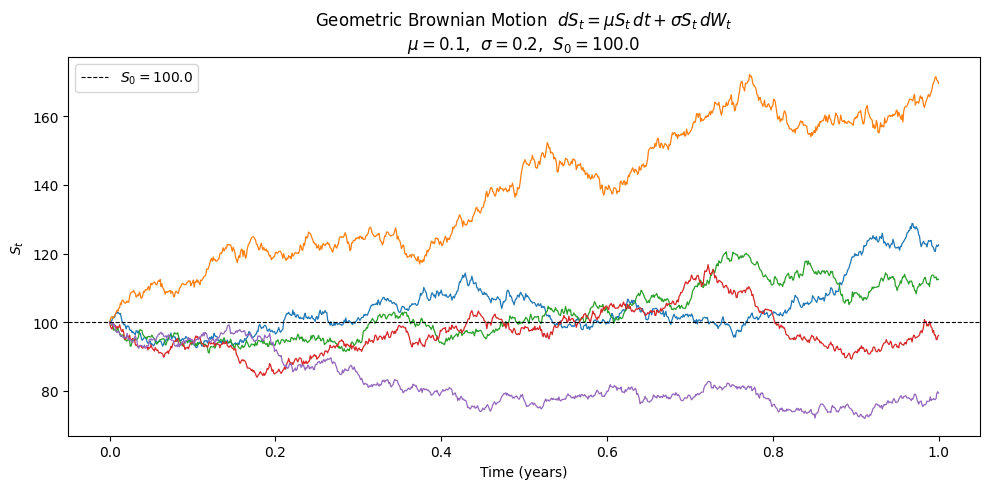

In [19]:
# --- Geometric Brownian Motion: dS_t = μ S_t dt + σ S_t dW_t ---

# parameters
mu    = 0.1      # drift
sigma = 0.2      # volatility
S0    = 100.0    # initial price
T     = 1.0      # total time (years)
n_steps = 1000   # number of time steps
n_paths = 5      # number of simulated paths

dt = T / n_steps
t  = np.linspace(0, T, n_steps + 1)

np.random.seed(42)

# Euler-Maruyama discretisation
#   S_{i+1} = S_i + μ S_i dt + σ S_i dW_i
#   dW_i ~ N(0, dt)
dW = np.random.normal(0.0, np.sqrt(dt), size=(n_paths, n_steps))

S = np.zeros((n_paths, n_steps + 1))
S[:, 0] = S0

for i in range(n_steps):
    S[:, i + 1] = S[:, i] + mu * S[:, i] * dt + sigma * S[:, i] * dW[:, i]

# plot
fig, ax = plt.subplots(figsize=(10, 5))
for path in S:
    ax.plot(t, path, linewidth=0.9)

ax.axhline(S0, color="black", linestyle="--", linewidth=0.8, label=f"$S_0 = {S0}$")
ax.set_title(r"Geometric Brownian Motion  $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$"
             f"\n$\mu={mu}$,  $\sigma={sigma}$,  $S_0={S0}$")
ax.set_xlabel("Time (years)")
ax.set_ylabel("$S_t$")
ax.legend()
plt.tight_layout()
plt.show()